# Adversarial Attacks on Perception

**Module 02 · Failures and Robustness** · Notebook 4 of 4

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/02_Failures_and_Robustness/04_adversarial_attacks.ipynb)

| Level | Time | Prerequisites | Standards |
|---|---|---|---|
| Intermediate | ~85 min | [03 · Out-of-distribution detection](03_out_of_distribution_detection.ipynb); basic PyTorch (autograd) | ISO/SAE 21434:2021, UN R155; ISO 21448:2022 (scope boundary) |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

By the end of this notebook, you will be able to:

1. Define adversarial examples, threat models and perturbation budgets (with units)
2. Implement FGSM and PGD correctly (true labels, clipping, projection, random start) and measure attack success versus budget on a trained model
3. Explain physical attacks (adversarial patches) and sensor attacks on cameras, LiDAR and multi-sensor fusion, with their primary sources
4. Evaluate defences honestly: adversarial training, input squeezing and the need for adaptive attacks
5. Place adversarial robustness in ISO/SAE 21434 TARA terminology and separate it from ISO 21448

## Setup and imports

The whole notebook runs **offline on a CPU in about a minute**: we attack a small convolutional network trained on scikit-learn's built-in handwritten digits.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from IPython.display import display

SEED = 42
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)  # tiny model: one thread is fastest and avoids CPU oversubscription
device = 'cpu'

OKABE = ['#E69F00', '#56B4E9', '#009E73', '#F0E442', '#0072B2', '#D55E00', '#CC79A7', '#000000']
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})
T0 = time.time()
print(f"PyTorch {torch.__version__} | NumPy {np.__version__}")

PyTorch 2.15.0+cpu | NumPy 2.5.4


---

## What are adversarial examples?

**Adversarial examples** are inputs deliberately modified so that a machine-learning model makes a mistake, while the modification is small by some measure.

### Threat model

| Dimension | Options |
|---|---|
| Attacker knowledge | **white-box** (model and gradients known) · **black-box** (queries only, or a surrogate model) |
| Goal | **untargeted** (any wrong class) · **targeted** (a chosen class, e.g. "speed limit" instead of "stop") |
| Budget | $\lVert\delta\rVert_\infty \le \varepsilon$ (each pixel changes by at most ε), $L_2$, or a **patch** (unbounded change in a small region) |
| Domain | **digital** (pixels after capture) · **physical** (stickers, objects, light, laser) |

### Fast Gradient Sign Method (FGSM)

$$x_{\mathrm{adv}} = \mathrm{clip}_{[0,1]}\!\big(x + \varepsilon \cdot \mathrm{sign}(\nabla_x L(f(x), y))\big)$$

- $x$ input with pixel values in **[0, 1]**; ε is in the **same units** (ε = 8/255 ≈ 0.031 is the common $L_\infty$ budget on CIFAR-10). We perturb **before** any normalisation.
- $y$ the **true label** (using the model's own prediction instead avoids "label leaking" in adversarial training, Kurakin et al., 2017).
- $L$ the cross-entropy loss; clipping keeps the image valid.

### Why do adversarial examples exist?

1. **High dimensionality:** many small changes add up in a dot product
2. **Local linearity:** networks behave approximately linearly around inputs (Goodfellow et al., 2015)
3. **Non-robust but predictive features:** models exploit features that are predictive yet imperceptible to humans (Ilyas et al., 2019)
4. **Optimisation for the average case:** training minimises average, not worst-case, loss

**Properties:** attacks often **transfer** between models (enabling black-box attacks); digital $L_p$ attacks can be **imperceptible**, whereas physical attacks are typically **visible but inconspicuous** (graffiti-like stickers).

### A documented example

Eykholt et al. (2018) placed black-and-white stickers on a real stop sign; a road-sign classifier then read it as a **Speed Limit 45** sign in laboratory and drive-by tests. This is an attack on a **camera-based classifier**, not on a vehicle in service.

---

## Experimental setup

- **Data:** scikit-learn `load_digits`, 10 classes, 8×8 grey-scale images scaled to [0, 1]; stratified 75% train / 25% test
- **Model:** small CNN (two convolutions, no BatchNorm), trained for a few seconds
- **Budgets:** these images have only 17 grey levels and 64 pixels, so the perturbation budgets that matter are larger than for natural images; we sweep ε from 0 to 0.3 in pixel units
- **Success rate** is computed only over test images the model classifies **correctly** without attack

In [2]:
digits = load_digits()
X = (digits.images / 16.0).astype(np.float32)
y = digits.target
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
to_t = lambda A: torch.from_numpy(np.asarray(A, dtype=np.float32)).unsqueeze(1)
xtr, ytr = to_t(X_tr), torch.from_numpy(y_tr)
xte, yte = to_t(X_te), torch.from_numpy(y_te)

class SmallCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.fc1 = nn.Linear(32 * 4 * 4, 64)
        self.fc2 = nn.Linear(64, n_classes)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)
        return self.fc2(F.relu(self.fc1(x.flatten(1))))

@torch.no_grad()
def accuracy(model, x, y):
    return (model(x).argmax(1) == y).float().mean().item()

def train(attack=None, epochs=30, seed=0):
    """Standard training, or adversarial training if `attack(model, x, y)` is given."""
    torch.manual_seed(seed)
    model = SmallCNN()
    opt = torch.optim.Adam(model.parameters(), lr=2e-3)
    for _ in range(epochs):
        perm = torch.randperm(len(xtr))
        for i in range(0, len(xtr), 128):
            b = perm[i:i + 128]
            xb, yb = xtr[b], ytr[b]
            if attack is not None:
                model.eval()                 # craft attacks with the model in inference mode
                xb = attack(model, xb, yb)   # ... using the TRUE labels
            model.train()
            opt.zero_grad()
            F.cross_entropy(model(xb), yb).backward()
            opt.step()
    return model.eval()

t = time.time()
model = train()
print(f"Standard model trained in {time.time() - t:.1f} s | clean test accuracy {accuracy(model, xte, yte):.3f}")

Standard model trained in 5.5 s | clean test accuracy 0.982


---

## Digital attack 1: FGSM

**Idea:** one step of size ε in the direction of the sign of the loss gradient (Goodfellow et al., 2015).
**Properties:** fast (one gradient), simple, often effective — but a single linear step is not the strongest attack within the budget.

For a **targeted** attack towards class $t$, step *down* the loss of the target: $x_{\mathrm{adv}} = \mathrm{clip}(x - \varepsilon\,\mathrm{sign}(\nabla_x L(f(x), t)))$.

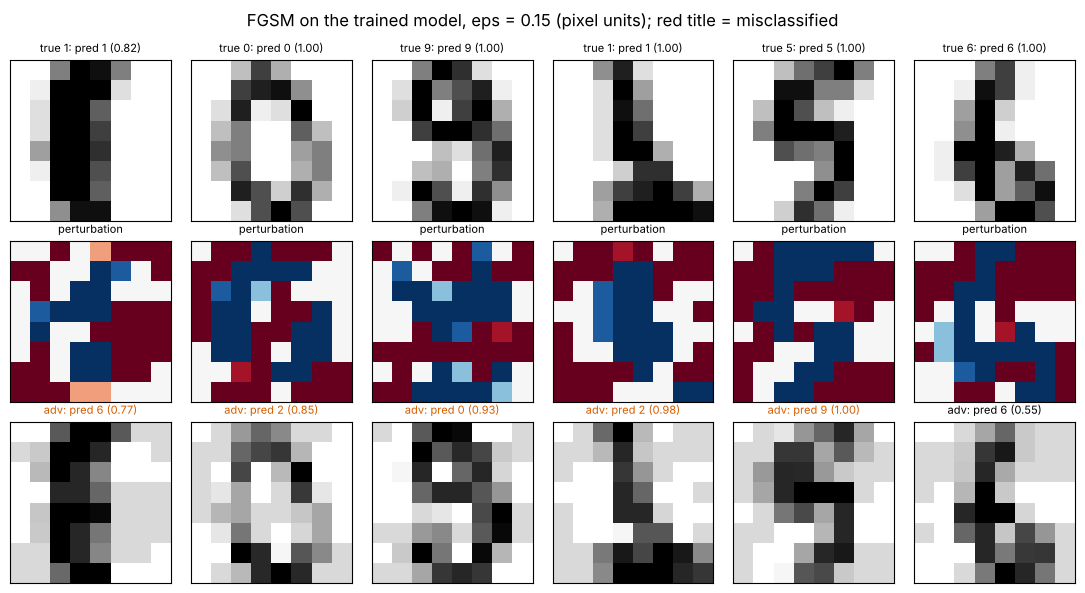

--- Text summary --- 5 of 6 shown images are misclassified after FGSM with eps=0.15; each pixel changed by at most 0.15.


In [3]:
@torch.enable_grad()
def fgsm(model, x, y, eps, target=None):
    """FGSM in pixel units. y: true labels (untargeted); target: class index or tensor (targeted)."""
    x = x.clone().detach().requires_grad_(True)
    logits = model(x)
    if target is None:
        loss = F.cross_entropy(logits, y)                       # maximise loss of the true class
        step = +1
    else:
        tgt = torch.full_like(y, target) if not torch.is_tensor(target) else target
        loss = F.cross_entropy(logits, tgt)                     # minimise loss of the target class
        step = -1
    grad, = torch.autograd.grad(loss, x)
    return (x + step * eps * grad.sign()).clamp(0, 1).detach()

eps_demo = 0.15
idx = np.arange(6)
x_adv = fgsm(model, xte[idx], yte[idx], eps_demo)
with torch.no_grad():
    p_clean = F.softmax(model(xte[idx]), 1)
    p_adv = F.softmax(model(x_adv), 1)

fig, axes = plt.subplots(3, len(idx), figsize=(11, 6))
for j in range(len(idx)):
    c0, c1 = p_clean[j].argmax().item(), p_adv[j].argmax().item()
    axes[0, j].imshow(xte[idx[j], 0], cmap='gray_r', vmin=0, vmax=1)
    axes[0, j].set_title(f"true {y_te[idx[j]]}: pred {c0} ({p_clean[j, c0]:.2f})", fontsize=8)
    axes[1, j].imshow((x_adv[j, 0] - xte[idx[j], 0]), cmap='RdBu_r', vmin=-eps_demo, vmax=eps_demo)
    axes[1, j].set_title('perturbation', fontsize=8)
    axes[2, j].imshow(x_adv[j, 0], cmap='gray_r', vmin=0, vmax=1)
    axes[2, j].set_title(f"adv: pred {c1} ({p_adv[j, c1]:.2f})", fontsize=8,
                         color=OKABE[5] if c1 != y_te[idx[j]] else 'black')
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle(f'FGSM on the trained model, eps = {eps_demo} (pixel units); red title = misclassified')
plt.tight_layout()
plt.show()

flipped = int((p_adv.argmax(1) != yte[idx]).sum())
print(f"--- Text summary --- {flipped} of {len(idx)} shown images are misclassified after FGSM "
      f"with eps={eps_demo}; each pixel changed by at most {eps_demo}.")

---

## Digital attack 2: PGD (projected gradient descent)

Madry et al. (2018): iterate small FGSM-like steps and **project** back into the ε-ball after each step:

1. **Random start:** $x^0 = \mathrm{clip}(x + u)$, $u \sim \mathcal{U}(-\varepsilon, \varepsilon)$
2. Repeat $K$ times: $x^{k+1} = \Pi_{\lVert x' - x\rVert_\infty \le \varepsilon}\Big(\mathrm{clip}\big(x^k + \alpha\,\mathrm{sign}(\nabla_x L(f(x^k), y))\big)\Big)$

with step size α (here α = 2.5·ε/K). PGD is the standard "first-order" attack for evaluating $L_\infty$ robustness: slower than FGSM but stronger.

In [4]:
@torch.enable_grad()
def pgd(model, x, y, eps, steps=10, alpha=None, random_start=True, target=None):
    alpha = alpha if alpha is not None else 2.5 * eps / steps
    x = x.clone().detach()
    x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1) if random_start else x.clone()
    tgt = None if target is None else (torch.full_like(y, target) if not torch.is_tensor(target) else target)
    for _ in range(steps):
        x_adv.requires_grad_(True)
        logits = model(x_adv)
        loss = F.cross_entropy(logits, y) if tgt is None else -F.cross_entropy(logits, tgt)
        grad, = torch.autograd.grad(loss, x_adv)
        x_adv = x_adv.detach() + alpha * grad.sign()
        x_adv = torch.min(torch.max(x_adv, x - eps), x + eps).clamp(0, 1)   # project, then clip
    return x_adv.detach()

print("PGD defined (L-infinity, random start, projection + clipping).")

PGD defined (L-infinity, random start, projection + clipping).


,Random sign noise,FGSM,PGD-10
eps,,,
0.000,0.000,0.000,0.000
0.025,0.002,0.036,0.038
0.050,0.002,0.127,0.131
0.075,0.007,0.247,0.278
0.100,0.025,0.403,0.446
0.150,0.038,0.708,0.812
0.200,0.045,0.934,0.980
0.300,0.188,0.986,1.000


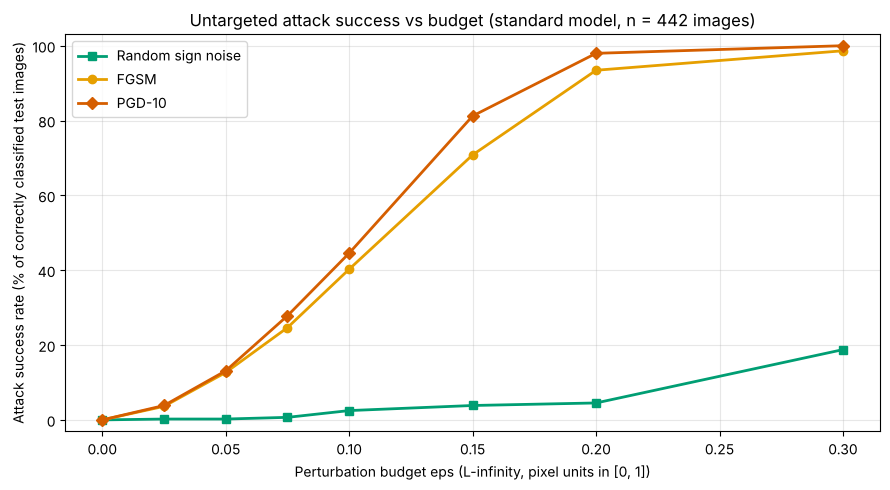

--- Derived ---
  Random sign noise : success at eps=0.1: 2.5%; smallest tested eps with >= 50% success: none in range
  FGSM              : success at eps=0.1: 40.3%; smallest tested eps with >= 50% success: 0.15
  PGD-10            : success at eps=0.1: 44.6%; smallest tested eps with >= 50% success: 0.15
  At eps=0.1, PGD succeeds 18x as often as random noise of the same size: adversarial perturbations are not random noise.


In [5]:
eps_list = [0.0, 0.025, 0.05, 0.075, 0.1, 0.15, 0.2, 0.3]
correct = (model(xte).argmax(1) == yte)
xc, yc = xte[correct], yte[correct]
torch.manual_seed(1)

def success_rate(model, x_adv, y):
    with torch.no_grad():
        return (model(x_adv).argmax(1) != y).float().mean().item()

rows = []
for e in eps_list:
    rand = (xc + e * torch.sign(torch.randn_like(xc))).clamp(0, 1)      # random +-eps noise, same budget
    rows.append({'eps': e,
                 'Random sign noise': success_rate(model, rand, yc),
                 'FGSM': success_rate(model, fgsm(model, xc, yc, e), yc) if e > 0 else 0.0,
                 'PGD-10': success_rate(model, pgd(model, xc, yc, e), yc) if e > 0 else 0.0})
attack_df = pd.DataFrame(rows).set_index('eps')
display(attack_df.round(3))

fig, ax = plt.subplots(figsize=(9, 5))
for col, c, m in [('Random sign noise', OKABE[2], 's'), ('FGSM', OKABE[0], 'o'), ('PGD-10', OKABE[5], 'D')]:
    ax.plot(attack_df.index, attack_df[col] * 100, marker=m, color=c, lw=2, label=col)
ax.set_xlabel('Perturbation budget eps (L-infinity, pixel units in [0, 1])')
ax.set_ylabel('Attack success rate (% of correctly classified test images)')
ax.set_title(f'Untargeted attack success vs budget (standard model, n = {len(yc)} images)')
ax.set_ylim(-3, 103)
ax.legend()
plt.tight_layout()
plt.show()

def eps_for(series, level=0.5):
    hit = series[series >= level]
    return hit.index[0] if len(hit) else None

print("--- Derived ---")
for col in attack_df.columns:
    e50 = eps_for(attack_df[col])
    print(f"  {col:18s}: success at eps=0.1: {attack_df.loc[0.1, col]:.1%}; "
          f"smallest tested eps with >= 50% success: {e50 if e50 is not None else 'none in range'}")
print(f"  At eps=0.1, PGD succeeds {attack_df.loc[0.1, 'PGD-10'] / max(attack_df.loc[0.1, 'Random sign noise'], 1e-9):.0f}x "
      "as often as random noise of the same size: adversarial perturbations are not random noise.")

### Targeted attack

Analogous to "stop sign → speed limit": we try to make every test image (not already of the target class) be classified as the digit **1**.

In [6]:
TARGET = 1
mask = yc != TARGET
xt, yt = xc[mask], yc[mask]
rows = []
for e in [0.05, 0.1, 0.15, 0.2, 0.3]:
    adv = pgd(model, xt, yt, e, steps=10, target=TARGET)
    with torch.no_grad():
        rows.append({'eps': e, 'targeted success (pred == 1)': (model(adv).argmax(1) == TARGET).float().mean().item()})
tgt_df = pd.DataFrame(rows).set_index('eps')
display(tgt_df.round(3))
print("--- Derived --- targeted PGD-10 success: " +
      ", ".join(f"eps={e}: {v:.0%}" for e, v in tgt_df.iloc[:, 0].items()))
print(f"At eps=0.15: untargeted PGD success {attack_df.loc[0.15, 'PGD-10']:.0%} vs targeted {tgt_df.loc[0.15].iloc[0]:.0%} - "
      "forcing one specific class needs a larger budget, but is what matters for e.g. sign substitution.")

,targeted success (pred == 1)
eps,
0.05,0.033
0.10,0.083
0.15,0.253
0.20,0.525
0.30,0.955


--- Derived --- targeted PGD-10 success: eps=0.05: 3%, eps=0.1: 8%, eps=0.15: 25%, eps=0.2: 53%, eps=0.3: 95%
At eps=0.15: untargeted PGD success 81% vs targeted 25% - forcing one specific class needs a larger budget, but is what matters for e.g. sign substitution.


---

## Physical-world attacks

Digital attacks change pixels *after* capture. A physical attacker must instead change the **world** so that the change survives:
1. **Printing** (limited colour gamut)
2. **Viewing angle and distance** (perspective, scale, resolution)
3. **Lighting and weather**
4. **Camera pipeline** (exposure, compression, motion blur)

Robust physical attacks therefore optimise over many transformations ("expectation over transformation") and accept **visible but inconspicuous** patterns.

**Key results (all on research systems, not on vehicles in service):**
- **Stickers on a stop sign** (Eykholt et al., CVPR 2018): road-sign classifiers misread the sign as *Speed Limit 45* in lab and drive-by tests.
- **Adversarial patch** (Brown et al., 2017): a universal, printable patch that makes a classifier output a chosen class when placed anywhere in the scene.

### Demonstration: a universal adversarial patch

We optimise one **3×3-pixel patch** (14% of the image) at a fixed position (bottom-right corner) that **lowers the accuracy on any digit** (untargeted, universal), using training images only, and evaluate on unseen test images. A random patch of the same size is the baseline. The patch is not bounded in ε — only in area. (On these 8×8 digits, small *targeted* patches that force one chosen class work poorly; real patch attacks on larger images are far more effective.)

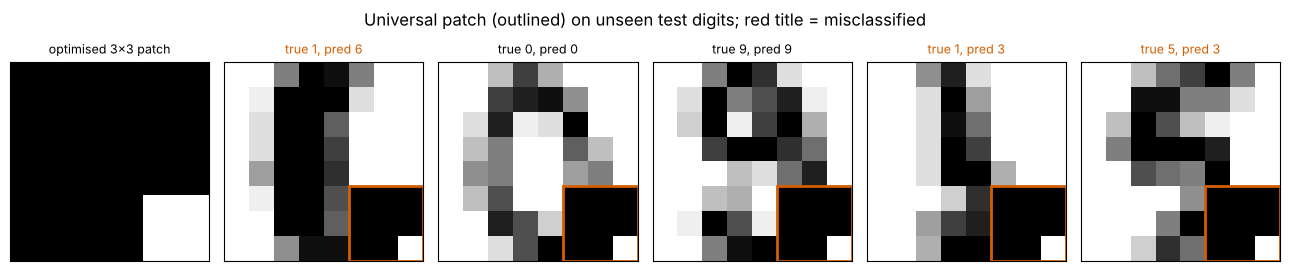

--- Derived (all test images) ---
  Accuracy without patch : 98.2%
  Accuracy, random patch : 86.2%
  Accuracy, optimised    : 43.1%  (drop vs random patch: 43.1 percentage points)
  Most frequent prediction with the optimised patch: digit 3 (221 of 450 images)


In [7]:
PS = 3
r0, c0 = 8 - PS, 8 - PS                  # bottom-right corner

def apply_patch(x, patch):
    x = x.clone()
    x[:, :, r0:r0 + PS, c0:c0 + PS] = patch
    return x

torch.manual_seed(3)
logit_p = torch.zeros(1, 1, PS, PS, requires_grad=True)           # patch = sigmoid(logit_p) in [0, 1]
opt_p = torch.optim.Adam([logit_p], lr=0.3)
for step in range(100):
    loss = -F.cross_entropy(model(apply_patch(xtr, torch.sigmoid(logit_p))), ytr)   # maximise training loss
    opt_p.zero_grad(); loss.backward(); opt_p.step()
patch = torch.sigmoid(logit_p).detach()

random_patch = torch.rand(1, 1, PS, PS)
with torch.no_grad():
    acc_clean = accuracy(model, xte, yte)
    acc_adv = accuracy(model, apply_patch(xte, patch), yte)
    acc_rand = accuracy(model, apply_patch(xte, random_patch), yte)
    pred_adv = model(apply_patch(xte, patch)).argmax(1)

fig, axes = plt.subplots(1, 6, figsize=(13, 2.8))
axes[0].imshow(patch[0, 0], cmap='gray_r', vmin=0, vmax=1); axes[0].set_title('optimised 3x3 patch', fontsize=9)
for j in range(5):
    axes[j + 1].imshow(apply_patch(xte[j:j + 1], patch)[0, 0], cmap='gray_r', vmin=0, vmax=1)
    axes[j + 1].add_patch(plt.Rectangle((c0 - 0.5, r0 - 0.5), PS, PS, fill=False, edgecolor=OKABE[5], lw=2))
    wrong = pred_adv[j].item() != y_te[j]
    axes[j + 1].set_title(f"true {y_te[j]}, pred {pred_adv[j].item()}", fontsize=9, color=OKABE[5] if wrong else 'black')
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle('Universal patch (outlined) on unseen test digits; red title = misclassified')
plt.tight_layout()
plt.show()

top = torch.bincount(pred_adv, minlength=10)
print("--- Derived (all test images) ---")
print(f"  Accuracy without patch : {acc_clean:.1%}")
print(f"  Accuracy, random patch : {acc_rand:.1%}")
print(f"  Accuracy, optimised    : {acc_adv:.1%}  (drop vs random patch: {100 * (acc_rand - acc_adv):.1f} percentage points)")
print(f"  Most frequent prediction with the optimised patch: digit {top.argmax().item()} "
      f"({top.max().item()} of {len(pred_adv)} images)")

---

## Sensor-level attacks

Beyond adversarial *inputs to a neural network*, attackers can target the **sensors** themselves:

### LiDAR spoofing
- **Attack:** a photodiode detects the LiDAR's pulses and a synchronised laser injects fake returns.
- **Evidence:** Petit et al. (Black Hat Europe 2015) relayed/spoofed returns in the laboratory and blinded a camera; Shin et al. (CHES 2017) created fake points and saturation ("illusion and dazzle"). **Cao et al. (ACM CCS 2019)** found that *blindly* spoofing points is insufficient because the machine-learning object detector does not report them as an obstacle; by **optimising** the spoofed points they spoofed obstacles close to the front of the victim vehicle in the Baidu Apollo LiDAR perception with a success rate of around 75%, and analysed the consequences at driving-decision level (e.g. emergency braking).
- **Effect:** phantom obstacles → emergency braking or unnecessary stops.

### Camera blinding
- **Attack:** bright light or lasers saturate the image sensor (Petit et al., 2015).
- **Effect:** temporary loss of camera perception.

### Attacks on multi-sensor fusion
- **Cao et al. (IEEE S&P 2021)** designed a physically realisable 3D object that is **missed by both camera and LiDAR** in a multi-sensor fusion perception system — sensor fusion is **not** an automatic defence.

### GNSS spoofing and radar jamming
- Falsified satellite signals shift the estimated position; radar interference or jamming reduces detection. Plausibility checks against odometry/IMU and map matching are standard mitigations.

> The difficulty ratings below are **illustrative** (they depend on attacker access, equipment and the target system); use them as a starting point for a TARA, not as facts.

In [8]:
sensor_attacks = pd.DataFrame([
    ('Camera', 'Adversarial patch / stickers', 'Misclassification of signs or objects', 'Medium',
     'Adversarial training, temporal/map plausibility, sensor diversity', 'Eykholt et al. 2018; Brown et al. 2017'),
    ('Camera', 'Laser / light blinding', 'Temporary blindness', 'Low',
     'Saturation detection, degraded-mode fallback, redundancy', 'Petit et al. 2015'),
    ('LiDAR', 'Spoofing (injected returns)', 'Phantom obstacle', 'High',
     'Pulse randomisation/authentication, cross-sensor plausibility', 'Shin et al. 2017; Cao et al. 2019'),
    ('LiDAR', 'Saturation / jamming', 'Lost points in a sector', 'Medium',
     'Anomaly detection on point statistics, redundancy', 'Shin et al. 2017'),
    ('Camera + LiDAR', 'Adversarial 3D object vs fusion', 'Object missed by both sensors', 'High',
     'Diverse fusion, robustness testing, runtime monitoring', 'Cao et al. 2021'),
    ('Radar', 'Jamming / interference', 'Reduced detection', 'Medium',
     'Interference detection, waveform diversity', '(general literature)'),
    ('GNSS', 'Spoofing', 'Wrong position', 'Medium',
     'IMU/odometry and map-matching plausibility checks', '(general literature)'),
], columns=['Sensor', 'Attack', 'Effect', 'Difficulty (illustrative)', 'Countermeasures', 'Primary source'])
display(sensor_attacks)
print("--- Text summary ---")
for _, r in sensor_attacks.iterrows():
    print(f"  {r['Sensor']:15s} | {r['Attack']:32s} | difficulty {r['Difficulty (illustrative)']:6s} | {r['Primary source']}")
print(f"\n{sensor_attacks['Sensor'].nunique()} sensor groups listed; every modality has demonstrated or plausible attacks.")

,Sensor,Attack,Effect,Difficulty (illustrative),Countermeasures,Primary source
0,Camera,Adversarial patch / stickers,Misclassification of signs or objects,Medium,"Adversarial training, temporal/map plausibilit...",Eykholt et al. 2018; Brown et al. 2017
1,Camera,Laser / light blinding,Temporary blindness,Low,"Saturation detection, degraded-mode fallback, ...",Petit et al. 2015
2,LiDAR,Spoofing (injected returns),Phantom obstacle,High,"Pulse randomisation/authentication, cross-sens...",Shin et al. 2017; Cao et al. 2019
3,LiDAR,Saturation / jamming,Lost points in a sector,Medium,"Anomaly detection on point statistics, redundancy",Shin et al. 2017
4,Camera + LiDAR,Adversarial 3D object vs fusion,Object missed by both sensors,High,"Diverse fusion, robustness testing, runtime mo...",Cao et al. 2021
5,Radar,Jamming / interference,Reduced detection,Medium,"Interference detection, waveform diversity",(general literature)
6,GNSS,Spoofing,Wrong position,Medium,IMU/odometry and map-matching plausibility checks,(general literature)


--- Text summary ---
  Camera          | Adversarial patch / stickers     | difficulty Medium | Eykholt et al. 2018; Brown et al. 2017
  Camera          | Laser / light blinding           | difficulty Low    | Petit et al. 2015
  LiDAR           | Spoofing (injected returns)      | difficulty High   | Shin et al. 2017; Cao et al. 2019
  LiDAR           | Saturation / jamming             | difficulty Medium | Shin et al. 2017
  Camera + LiDAR  | Adversarial 3D object vs fusion  | difficulty High   | Cao et al. 2021
  Radar           | Jamming / interference           | difficulty Medium | (general literature)
  GNSS            | Spoofing                         | difficulty Medium | (general literature)

5 sensor groups listed; every modality has demonstrated or plausible attacks.


---

## Defences

### 1. Adversarial training
Train on adversarial examples generated **on the fly with the true labels**: $\min_\theta \mathbb{E}\,\max_{\lVert\delta\rVert\le\varepsilon} L(f_\theta(x+\delta), y)$ (Madry et al., 2018).
- **PGD adversarial training** is the standard; plain FGSM training can suffer *catastrophic overfitting*, while FGSM with random initialisation can work when tuned carefully (Wong et al., 2020).
- **Costs:** more training compute; usually **lower clean accuracy**; robustness only for the threat model trained against.

### 2. Input transformation and detection
E.g. **feature squeezing** (Xu et al., 2018): reduce bit depth or smooth the input and compare predictions. Cheap — but such defences are often broken by **adaptive attacks** that take the transformation into account (Athalye et al., 2018, "obfuscated gradients").

### 3. Certified defences
**Randomised smoothing** (Cohen et al., 2019), interval bound propagation, Lipschitz constraints: provable guarantees within a radius, usually at a cost in accuracy and with small certified radii.

### 4. System-level measures
Redundant and diverse sensing, plausibility checks, runtime monitoring, secure update processes — see the corrected fusion discussion below.

**Evaluation rule:** report robustness against the **strongest adaptive attack** you can construct, never only against the attack used during development.

PGD adversarial training (eps=0.15, 5 steps) took 20.5 s


,standard: accuracy under PGD-10,adv. trained: accuracy under PGD-10
eps,,
0.000,0.982,0.980
0.025,0.944,0.971
0.050,0.851,0.944
0.075,0.707,0.916
0.100,0.547,0.864
0.150,0.180,0.702
0.200,0.024,0.471
0.300,0.000,0.016


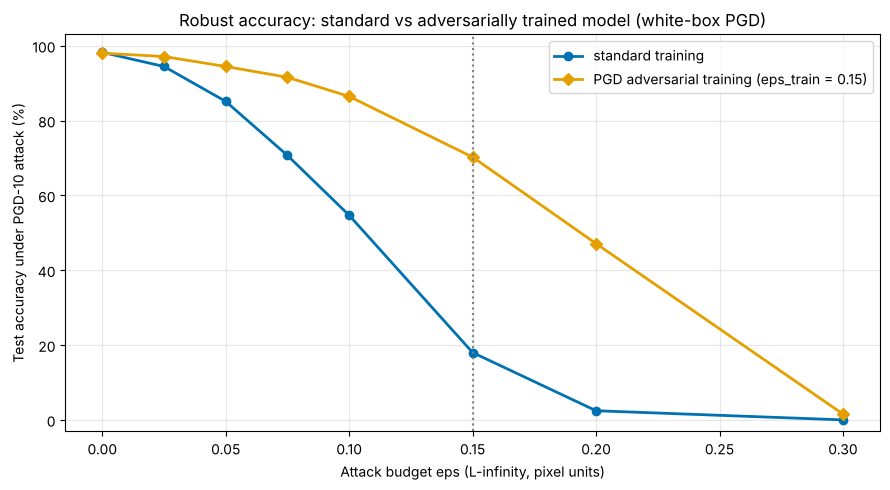

--- Derived ---
  Clean accuracy: standard 98.2%, adversarially trained 98.0% (change -0.2 percentage points)
  At eps=0.15: standard 18.0%, adversarially trained 70.2%
  At eps=0.3 (twice the training budget): standard 0.0%, adversarially trained 1.6%
  Robustness is obtained for the trained budget; beyond it, protection falls away.


In [9]:
EPS_TRAIN = 0.15
t = time.time()
model_at = train(attack=lambda m, xb, yb: pgd(m, xb, yb, EPS_TRAIN, steps=5), epochs=30)
print(f"PGD adversarial training (eps={EPS_TRAIN}, 5 steps) took {time.time() - t:.1f} s")

torch.manual_seed(2)
rows = []
for e in eps_list:
    row = {'eps': e}
    for name, m in [('standard', model), ('adv. trained', model_at)]:
        row[f'{name}: accuracy under PGD-10'] = accuracy(m, pgd(m, xte, yte, e) if e > 0 else xte, yte)
    rows.append(row)
robust_df = pd.DataFrame(rows).set_index('eps')
display(robust_df.round(3))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(robust_df.index, robust_df.iloc[:, 0] * 100, marker='o', color=OKABE[4], lw=2, label='standard training')
ax.plot(robust_df.index, robust_df.iloc[:, 1] * 100, marker='D', color=OKABE[0], lw=2,
        label=f'PGD adversarial training (eps_train = {EPS_TRAIN})')
ax.axvline(EPS_TRAIN, color='grey', ls=':')
ax.set_xlabel('Attack budget eps (L-infinity, pixel units)')
ax.set_ylabel('Test accuracy under PGD-10 attack (%)')
ax.set_title('Robust accuracy: standard vs adversarially trained model (white-box PGD)')
ax.set_ylim(-3, 103)
ax.legend()
plt.tight_layout()
plt.show()

s, a = robust_df.iloc[:, 0], robust_df.iloc[:, 1]
print("--- Derived ---")
print(f"  Clean accuracy: standard {s.loc[0.0]:.1%}, adversarially trained {a.loc[0.0]:.1%} "
      f"(change {100 * (a.loc[0.0] - s.loc[0.0]):+.1f} percentage points)")
print(f"  At eps={EPS_TRAIN}: standard {s.loc[EPS_TRAIN]:.1%}, adversarially trained {a.loc[EPS_TRAIN]:.1%}")
print(f"  At eps=0.3 (twice the training budget): standard {s.loc[0.3]:.1%}, adversarially trained {a.loc[0.3]:.1%}")
print("  Robustness is obtained for the trained budget; beyond it, protection falls away.")

### Input squeezing — and why defences need adaptive evaluation

We add a non-differentiable pre-processing step that reduces each pixel to **1 bit** (threshold at 0.5) before the standard model, and evaluate it twice:
- **non-adaptive:** attacks crafted on the *undefended* model and then fed through the squeezer;
- **adaptive:** the attacker knows the squeezer and attacks the whole pipeline, using the *straight-through* gradient approximation through the quantiser (BPDA, Athalye et al., 2018).

Only the adaptive number is a meaningful robustness claim. Note also that these digits are almost binary, which makes 1-bit squeezing unusually effective; on natural camera images bit-depth reduction gives far less protection.

,undefended,"squeezed, non-adaptive attack","squeezed, adaptive (BPDA) attack"
eps,,,
0.0,0.982,0.918,0.918
0.1,0.536,0.771,0.789
0.2,0.020,0.438,0.436
0.3,0.000,0.244,0.209


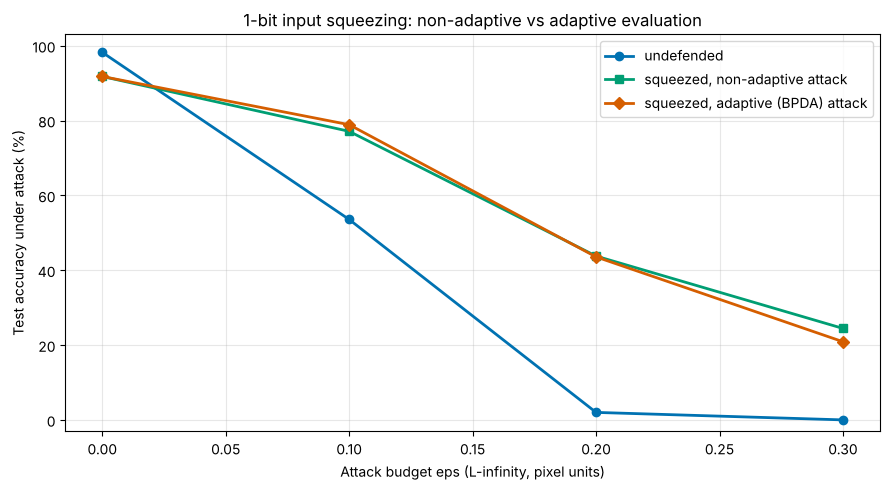

--- Derived ---
  eps=0.0: undefended 98.2% | squeezed vs non-adaptive 91.8% | squeezed vs adaptive 91.8%
  eps=0.1: undefended 53.6% | squeezed vs non-adaptive 77.1% | squeezed vs adaptive 78.9%
  eps=0.2: undefended 2.0% | squeezed vs non-adaptive 43.8% | squeezed vs adaptive 43.6%
  eps=0.3: undefended 0.0% | squeezed vs non-adaptive 24.4% | squeezed vs adaptive 20.9%
  At eps=0.3, the adaptive attack changes the defended accuracy by -3.6 percentage points relative to the non-adaptive evaluation.
  -> Here squeezing keeps part of its benefit under adaptive attack: on near-binary digits most
     pixels need a change of about 0.5 to flip, which exceeds these budgets. This is a property of
     the data, not a general defence; it must be re-checked with adaptive attacks for real images.
  Clean accuracy cost of squeezing: -6.4 percentage points.


In [10]:
def squeeze(x, bits=1):
    levels = 2 ** bits - 1
    return torch.round(x * levels) / levels

class Squeezed(nn.Module):
    """Defended pipeline f(squeeze(x)). bpda=True: identity gradient through the quantiser."""
    def __init__(self, base, bpda=False):
        super().__init__(); self.base, self.bpda = base, bpda
    def forward(self, x):
        xs = squeeze(x)
        if self.bpda:
            xs = x + (xs - x).detach()      # forward: squeezed; backward: identity
        return self.base(xs)

defended = Squeezed(model).eval()
defended_bpda = Squeezed(model, bpda=True).eval()
torch.manual_seed(4)
rows = []
for e in [0.0, 0.1, 0.2, 0.3]:
    if e == 0:
        rows.append({'eps': e, 'undefended': accuracy(model, xte, yte), 'squeezed, non-adaptive attack': accuracy(defended, xte, yte),
                     'squeezed, adaptive (BPDA) attack': accuracy(defended, xte, yte)})
        continue
    adv_transfer = pgd(model, xte, yte, e)                 # attack crafted on the undefended model
    adv_adaptive = pgd(defended_bpda, xte, yte, e, steps=10)
    rows.append({'eps': e, 'undefended': accuracy(model, adv_transfer, yte),
                 'squeezed, non-adaptive attack': accuracy(defended, adv_transfer, yte),
                 'squeezed, adaptive (BPDA) attack': accuracy(defended, adv_adaptive, yte)})
sq_df = pd.DataFrame(rows).set_index('eps')
display(sq_df.round(3))

fig, ax = plt.subplots(figsize=(9, 5))
for col, c, m in zip(sq_df.columns, [OKABE[4], OKABE[2], OKABE[5]], ['o', 's', 'D']):
    ax.plot(sq_df.index, sq_df[col] * 100, marker=m, color=c, lw=2, label=col)
ax.set_xlabel('Attack budget eps (L-infinity, pixel units)')
ax.set_ylabel('Test accuracy under attack (%)')
ax.set_title('1-bit input squeezing: non-adaptive vs adaptive evaluation')
ax.set_ylim(-3, 103)
ax.legend()
plt.tight_layout()
plt.show()
print("--- Derived ---")
for e, r in sq_df.iterrows():
    print(f"  eps={e}: undefended {r.iloc[0]:.1%} | squeezed vs non-adaptive {r.iloc[1]:.1%} | "
          f"squeezed vs adaptive {r.iloc[2]:.1%}")
gap = sq_df.iloc[-1, 1] - sq_df.iloc[-1, 2]
print(f"  At eps={sq_df.index[-1]}, the adaptive attack changes the defended accuracy by {-100 * gap:+.1f} percentage "
      "points relative to the non-adaptive evaluation.")
if gap > 0.10:
    print("  -> The non-adaptive evaluation substantially overstated robustness (gradient masking).")
else:
    print("  -> Here squeezing keeps part of its benefit under adaptive attack: on near-binary digits most")
    print("     pixels need a change of about 0.5 to flip, which exceeds these budgets. This is a property of")
    print("     the data, not a general defence; it must be re-checked with adaptive attacks for real images.")
print(f"  Clean accuracy cost of squeezing: {100 * (sq_df.iloc[0, 1] - sq_df.iloc[0, 0]):+.1f} percentage points.")

### Sensor fusion as a defence — what it can and cannot do

A tempting but **wrong** argument is "if the camera is fooled by a sticker, trust the LiDAR — it still sees the stop sign". **LiDAR measures geometry and reflectivity; it cannot read sign semantics** (STOP vs a speed limit). It can confirm that *a sign-shaped object exists*, not *which* sign it is.

Useful cross-checks for sign semantics instead:
- **HD-map and navigation priors** (is a stop sign expected at this intersection?)
- **Temporal and multi-view consistency** (does the class stay stable as the vehicle approaches?)
- **Plausibility rules** (a 45 mph limit on a stop-controlled urban approach is implausible)
- **Diverse classifiers** (different architectures and training data reduce transferability)

And for objects: fusion raises the bar, but **one physical object can fool both camera and LiDAR** (Cao et al., 2021). Fusion is a mitigation to be evaluated with attacks, not a guarantee.

---

## ISO/SAE 21434 and UN R155: where adversarial attacks belong

**Scope boundary.** Intentional manipulation — adversarial patches, spoofing, jamming — is a **cybersecurity** concern, handled by **ISO/SAE 21434:2021** and, for type approval, **UN Regulation No. 155** (cybersecurity management system) and **No. 156** (software update management system). **ISO 21448 (SOTIF) does not address intentional attacks**; it covers hazards from functional insufficiencies and reasonably foreseeable misuse. In the EU, R155/R156 have applied to new vehicle types since July 2022 and to all newly registered vehicles since July 2024.

### TARA terminology (ISO/SAE 21434, clause 15)

| Step | Output |
|---|---|
| Asset identification | Assets with cybersecurity properties (e.g. integrity of the camera object list) |
| Threat scenarios and damage scenarios | e.g. "manipulated stop sign → vehicle does not stop" |
| **Impact rating** | per category **Safety, Financial, Operational, Privacy**: *Severe / Major / Moderate / Negligible* |
| Attack path analysis | steps the attacker needs |
| **Attack feasibility rating** | *High / Medium / Low / Very low* — e.g. **attack-potential based** (elapsed time, expertise, knowledge of the item, window of opportunity, equipment), CVSS-based or attack-vector based |
| **Risk value** | **1 (lowest) – 5 (highest)** from impact × feasibility (example matrix in informative Annex H) |
| **Risk treatment** | *avoid, reduce, share* or *retain*; reduction leads to **cybersecurity goals** and claims |

The terms "likelihood" and "HIGH/MEDIUM risk" are not ISO/SAE 21434 terminology.

The same tables are implemented in the course toolkit as `avsafety.iso21434` (`attack_potential`, `feasibility_from_potential`, `risk_value`).

In [11]:
# Attack-potential approach (ISO/SAE 21434 Annex G, values from ISO/IEC 18045) and example risk matrix (Annex H)
ELAPSED_TIME = {'<=1 day': 0, '<=1 week': 1, '<=1 month': 4, '<=6 months': 17, '>6 months': 19}
EXPERTISE = {'layman': 0, 'proficient': 3, 'expert': 6, 'multiple experts': 8}
KNOWLEDGE = {'public': 0, 'restricted': 3, 'confidential': 7, 'strictly confidential': 11}
WINDOW = {'unlimited': 0, 'easy': 1, 'moderate': 4, 'difficult': 10}
EQUIPMENT = {'standard': 0, 'specialized': 4, 'bespoke': 7, 'multiple bespoke': 9}
RISK_MATRIX = {
    'Severe':     {'Very Low': 2, 'Low': 3, 'Medium': 4, 'High': 5},
    'Major':      {'Very Low': 1, 'Low': 2, 'Medium': 3, 'High': 4},
    'Moderate':   {'Very Low': 1, 'Low': 2, 'Medium': 2, 'High': 3},
    'Negligible': {'Very Low': 1, 'Low': 1, 'Medium': 1, 'High': 1},
}

def feasibility_from_potential(ap):
    return 'High' if ap <= 13 else 'Medium' if ap <= 19 else 'Low' if ap <= 24 else 'Very Low'

print("> Illustrative data: the factor ratings below are assumptions for a fictional vehicle, for teaching only.")
threats = pd.DataFrame([
    # threat, damage scenario, impact (safety), elapsed, expertise, knowledge, window, equipment
    ('Adversarial stickers on stop sign', 'Vehicle does not stop at junction', 'Severe',
     '<=1 month', 'expert', 'restricted', 'unlimited', 'standard'),
    ('LiDAR spoofing (phantom obstacle)', 'Unnecessary emergency braking', 'Severe',
     '<=6 months', 'expert', 'restricted', 'moderate', 'bespoke'),
    ('Camera laser blinding', 'Temporary loss of camera perception', 'Major',
     '<=1 week', 'proficient', 'public', 'easy', 'standard'),
    ('GNSS spoofing', 'Wrong localisation / route', 'Major',
     '<=1 month', 'proficient', 'public', 'moderate', 'specialized'),
    ('CAN injection via diagnostic port', 'Manipulated actuator commands', 'Severe',
     '<=1 week', 'proficient', 'restricted', 'difficult', 'standard'),
    ('Compromise of OTA update server', 'Malicious perception software', 'Severe',
     '>6 months', 'multiple experts', 'strictly confidential', 'unlimited', 'bespoke'),
], columns=['Threat', 'Damage_scenario', 'Impact_S', 'Elapsed', 'Expertise', 'Knowledge', 'Window', 'Equipment'])

threats['Attack_potential'] = (threats['Elapsed'].map(ELAPSED_TIME) + threats['Expertise'].map(EXPERTISE)
                               + threats['Knowledge'].map(KNOWLEDGE) + threats['Window'].map(WINDOW)
                               + threats['Equipment'].map(EQUIPMENT))
threats['Feasibility'] = threats['Attack_potential'].apply(feasibility_from_potential)
threats['Risk_value'] = [RISK_MATRIX[i][f] for i, f in zip(threats['Impact_S'], threats['Feasibility'])]
threats['Treatment'] = np.where(threats['Risk_value'] >= 4, 'reduce', np.where(threats['Risk_value'] == 3, 'reduce or share', 'retain (document rationale)'))
display(threats[['Threat', 'Impact_S', 'Attack_potential', 'Feasibility', 'Risk_value', 'Treatment']])

try:  # optional cross-check with the course toolkit, if it is installed
    from avsafety.iso21434 import attack_potential, feasibility_from_potential as fp, risk_value
    ok = all(attack_potential(r.Elapsed, r.Expertise, r.Knowledge, r.Window, r.Equipment) == r.Attack_potential
             and risk_value(r.Impact_S, fp(r.Attack_potential)) == r.Risk_value for r in threats.itertuples())
    print(f"Cross-check with avsafety.iso21434: {'identical' if ok else 'MISMATCH'}")
except ImportError:
    print("(avsafety not installed - cross-check skipped)")

print("\n--- Risk ranking (derived) ---")
for _, r in threats.sort_values('Risk_value', ascending=False).iterrows():
    print(f"  risk {r['Risk_value']} | AP={r['Attack_potential']:2d} ({r['Feasibility']:8s}) | impact {r['Impact_S']:6s} | "
          f"{r['Threat']} -> {r['Treatment']}")

> Illustrative data: the factor ratings below are assumptions for a fictional vehicle, for teaching only.


,Threat,Impact_S,Attack_potential,Feasibility,Risk_value,Treatment
0,Adversarial stickers on stop sign,Severe,13,High,5,reduce
1,LiDAR spoofing (phantom obstacle),Severe,37,Very Low,2,retain (document rationale)
2,Camera laser blinding,Major,5,High,4,reduce
3,GNSS spoofing,Major,15,Medium,3,reduce or share
4,CAN injection via diagnostic port,Severe,17,Medium,4,reduce
5,Compromise of OTA update server,Severe,45,Very Low,2,retain (document rationale)


Cross-check with avsafety.iso21434: identical

--- Risk ranking (derived) ---
  risk 5 | AP=13 (High    ) | impact Severe | Adversarial stickers on stop sign -> reduce
  risk 4 | AP= 5 (High    ) | impact Major  | Camera laser blinding -> reduce
  risk 4 | AP=17 (Medium  ) | impact Severe | CAN injection via diagnostic port -> reduce
  risk 3 | AP=15 (Medium  ) | impact Major  | GNSS spoofing -> reduce or share
  risk 2 | AP=37 (Very Low) | impact Severe | LiDAR spoofing (phantom obstacle) -> retain (document rationale)
  risk 2 | AP=45 (Very Low) | impact Severe | Compromise of OTA update server -> retain (document rationale)


---

## Safety perspective

- **Two standards, one vehicle.** Adversarial robustness is a **cybersecurity** property (ISO/SAE 21434, UN R155). But the *same* model weakness — sensitivity to small input changes — also matters for **SOTIF**: natural perturbations (noise, blur, weather) can act as triggering conditions for performance insufficiencies. Robustness testing therefore feeds both the TARA ([05 · TARA](../05_Cybersecurity_ISO21434/02_tara.ipynb), [05 · Attack surface analysis](../05_Cybersecurity_ISO21434/03_attack_surface_analysis.ipynb)) and the SOTIF analysis ([04 · SOTIF fundamentals](../04_SOTIF_ISO21448/01_sotif_fundamentals.ipynb)).
- **AI-specific assurance.** ISO/PAS 8800:2024 asks for robustness to be specified and verified for AI components — see [06 · AI safety standards](../06_AI_Safety_ISO_PAS_8800/01_ai_safety_standards.ipynb).
- **Interaction of safety and security arguments.** A safety case for an AI perception component must address attacks explicitly; see the GSN pattern by Patel & Jung (2026) in the references and [08 · Safety case (GSN)](../08_Standards_Regulation_and_Safety_Case/04_safety_case_gsn.ipynb).
- **Detection at runtime** (OOD/anomaly monitors from Notebook 03) can flag some attacks but is itself attackable; it is one layer of defence in depth.

---

## Exercise: security requirements for a campus shuttle

**Task:** for a driverless campus shuttle, derive cybersecurity requirements against perception attacks.

1. Which assets and damage scenarios are relevant?
2. Rate impact (S/F/O/P) and attack feasibility (attack potential) for at least three threats.
3. Determine the risk values and treatment decisions.
4. Formulate cybersecurity goals and test methods (including adaptive attacks).
5. What must be monitored in operation (UN R155 requires monitoring and response)?

In [12]:
# TODO: complete your TARA (use the dictionaries defined above)
your_tara = pd.DataFrame({
    'Threat': [],          # e.g. 'Sticker on campus entrance stop sign'
    'Impact_S': [],        # Severe, Major, Moderate, Negligible
    'Elapsed': [], 'Expertise': [], 'Knowledge': [], 'Window': [], 'Equipment': [],
    'Cybersecurity_goal': [],
    'Verification': [],    # e.g. 'PGD and patch attacks, adaptive evaluation'
})
if len(your_tara) > 0:
    your_tara['Attack_potential'] = (your_tara['Elapsed'].map(ELAPSED_TIME) + your_tara['Expertise'].map(EXPERTISE)
                                     + your_tara['Knowledge'].map(KNOWLEDGE) + your_tara['Window'].map(WINDOW)
                                     + your_tara['Equipment'].map(EQUIPMENT))
    your_tara['Feasibility'] = your_tara['Attack_potential'].apply(feasibility_from_potential)
    your_tara['Risk_value'] = [RISK_MATRIX[i][f] for i, f in zip(your_tara['Impact_S'], your_tara['Feasibility'])]
    display(your_tara)
else:
    print("Add your threats above.")
print("\nReflection questions:")
print("  1. How do you balance robustness against clean accuracy and compute cost?")
print("  2. What is the cost of a false alarm from an attack detector?")
print("  3. How do you keep defences up to date as new attacks are published?")
print(f"\nNotebook runtime: {time.time() - T0:.1f} s")

Add your threats above.

Reflection questions:
  1. How do you balance robustness against clean accuracy and compute cost?
  2. What is the cost of a false alarm from an attack detector?
  3. How do you keep defences up to date as new attacks are published?

Notebook runtime: 54.4 s


---

## Key takeaways

### Attacks
- **Digital:** FGSM (one step) and PGD (iterative, projected, random start) — with ε stated in input units and images clipped to the valid range; on our trained model, PGD is far more effective than random noise of the same size
- **Physical:** stickers and patches (visible but inconspicuous); a 3×3 universal patch already lowers the small model's accuracy far more than a random patch
- **Sensor:** LiDAR spoofing (Cao et al., 2019), camera blinding, and attacks that defeat camera–LiDAR fusion (Cao et al., 2021)

### Defences
1. **Adversarial training** (PGD-AT): real robustness within the trained budget, at a cost in clean accuracy and compute
2. **Input transformations/detectors:** cheap, but must be evaluated with **adaptive** attacks
3. **Certified defences:** guarantees within small radii
4. **System measures:** diverse sensing, map and temporal plausibility, monitoring — fusion is not a guarantee, and LiDAR cannot read signs

### Standards
- Attacks belong to **ISO/SAE 21434** and **UN R155/R156**, not to ISO 21448
- TARA uses **impact ratings**, **attack feasibility** and **risk values 1–5**, not "likelihood"

---

## Self-assessment

1. What is the difference between FGSM and PGD, and why is PGD the standard for evaluating robustness?
2. Why must ε always be stated together with the input scale (and the norm)?
3. Describe two physical-world constraints that make adversarial patches harder than digital attacks.
4. Can a LiDAR sensor correct a camera that misreads a manipulated stop sign? What cross-checks would help?
5. Under ISO/SAE 21434, which ratings determine the risk value of the threat "stickers on a stop sign", and which treatment options exist?
6. Why is a defence evaluated only with attacks crafted on the undefended model not a valid robustness claim?

<details>
<summary><b>Show answers</b></summary>

1. FGSM takes one step of size ε along the gradient sign; PGD takes many smaller steps from a random start and projects back into the ε-ball each time. PGD explores the allowed region better and finds stronger adversarial examples, so robustness against PGD is a more meaningful (though still not complete) claim.
2. ε = 0.03 means something completely different for pixels in [0, 1], in [0, 255] or after normalisation, and for L∞ versus L2. Without units, results are not comparable.
3. Any two of: printing (limited colours), varying viewing angle and distance, lighting/weather, the camera pipeline (exposure, blur, compression); the attacker must optimise over transformations and the patch becomes visible.
4. No — LiDAR measures geometry and reflectivity, not the printed symbol. Useful checks: HD-map priors, temporal and multi-view consistency, plausibility of the sign at that location, diverse classifiers.
5. The **impact rating** (here mainly the safety category, e.g. *Severe*) and the **attack feasibility rating** (e.g. from attack potential), combined through the risk matrix into a **risk value 1–5**. Treatment options: **avoid, reduce, share, retain**.
6. Such attacks ignore the defence; a non-differentiable or randomised pre-processing step can merely hide useful gradients (gradient masking). An attacker who knows the defence attacks the whole pipeline, e.g. with straight-through (BPDA) gradients or expectation over transformations. Only robustness measured against such adaptive attacks counts — in our digits example squeezing kept part of its benefit, but only because the data are nearly binary.

</details>

---

## References

**Attacks and defences**
- Goodfellow, I., Shlens, J., Szegedy, C. (2015). Explaining and Harnessing Adversarial Examples. *ICLR*. arXiv:1412.6572
- Kurakin, A., Goodfellow, I., Bengio, S. (2017). Adversarial Machine Learning at Scale. *ICLR*. arXiv:1611.01236
- Madry, A., Makelov, A., Schmidt, L., Tsipras, D., Vladu, A. (2018). Towards Deep Learning Models Resistant to Adversarial Attacks. *ICLR*. arXiv:1706.06083
- Wong, E., Rice, L., Kolter, J. Z. (2020). Fast is better than free: Revisiting adversarial training. *ICLR*. arXiv:2001.03994
- Ilyas, A., Santurkar, S., Tsipras, D., et al. (2019). Adversarial Examples Are Not Bugs, They Are Features. *NeurIPS*. arXiv:1905.02175
- Xu, W., Evans, D., Qi, Y. (2018). Feature Squeezing: Detecting Adversarial Examples in Deep Neural Networks. *NDSS*. arXiv:1704.01155
- Athalye, A., Carlini, N., Wagner, D. (2018). Obfuscated Gradients Give a False Sense of Security. *ICML*. arXiv:1802.00420
- Cohen, J., Rosenfeld, E., Kolter, J. Z. (2019). Certified Adversarial Robustness via Randomized Smoothing. *ICML*. arXiv:1902.02918

**Physical and sensor attacks**
- Eykholt, K., Evtimov, I., Fernandes, E., et al. (2018). Robust Physical-World Attacks on Deep Learning Visual Classification. *CVPR*. https://doi.org/10.1109/CVPR.2018.00175
- Brown, T. B., Mané, D., Roy, A., Abadi, M., Gilmer, J. (2017). Adversarial Patch. arXiv:1712.09665
- Petit, J., Stottelaar, B., Feiri, M., Kargl, F. (2015). Remote Attacks on Automated Vehicles Sensors: Experiments on Camera and LiDAR. *Black Hat Europe*. https://www.blackhat.com/docs/eu-15/materials/eu-15-Petit-Self-Driving-And-Connected-Cars-Fooling-Sensors-And-Tracking-Drivers-wp1.pdf
- Shin, H., Kim, D., Kwon, Y., Kim, Y. (2017). Illusion and Dazzle: Adversarial Optical Channel Exploits Against Lidars for Automotive Applications. *CHES 2017*, LNCS. https://doi.org/10.1007/978-3-319-66787-4_22
- Cao, Y., Xiao, C., Cyr, B., et al. (2019). Adversarial Sensor Attack on LiDAR-based Perception in Autonomous Driving. *ACM CCS*. https://doi.org/10.1145/3319535.3339815
- Cao, Y., Wang, N., Xiao, C., et al. (2021). Invisible for both Camera and LiDAR: Security of Multi-Sensor Fusion based Perception in Autonomous Driving Under Physical-World Attacks. *IEEE S&P*. https://doi.org/10.1109/SP40001.2021.00076

**Standards and regulation**
- ISO/SAE 21434:2021. *Road vehicles — Cybersecurity engineering*.
- UN Regulation No. 155 (cybersecurity and cybersecurity management system) and No. 156 (software update and software update management system), UNECE WP.29.
- UK Vehicle Certification Agency. *Cyber security and software updating* (application dates). https://www.vehicle-certification-agency.gov.uk/connected-and-automated-vehicles/cyber-security-and-software-updating/
- ISO 21448:2022. *Road vehicles — Safety of the intended functionality*.
- ISO/PAS 8800:2024. *Road vehicles — Safety and artificial intelligence*.

**Related work by the author**
- Patel, M., Jung, R. (2026). Integrating Cybersecurity Into the AI Safety Assurance Argument: A GSN Pattern for AI-Based Perception Components in Highly Automated Driving. In *Computer Safety, Reliability, and Security. SAFECOMP 2026 Workshops*, LNCS, pp. 763–779. Springer. https://doi.org/10.1007/978-3-032-35506-5_55

---

## Further practice

External repository (the author's companion workshop):
- [Notebook 04 — Adversarial Attacks](https://github.com/milinpatel07/AI-Perception-Safety-Workshop/blob/main/notebooks/04_adversarial_attacks.ipynb)

**Module 02 complete.** You have covered real-world incidents, corner cases, out-of-distribution detection and adversarial attacks. Module 03 turns to functional safety (ISO 26262); SOTIF follows in Module 04 and cybersecurity in Module 05.

---

**Navigation:** ← [Out-of-distribution detection](03_out_of_distribution_detection.ipynb) · [Module index](README.md) · [Module 03 · Functional Safety](../03_Functional_Safety_ISO26262/README.md) →